# 10. class weightの適用範囲と8群性能

ERM・Group DRO（global class weight）・Group DRO（subgroup class weight）を同じモデルで比べ、8群の性能がどう変わるかを見る。ResNetとSpatial LoRA（stage3–4+fc）で同じ図を並べ、Spatial LoRAにはtwo-stageのDROも加える。

| モデル | 学習手順 | ERM | DRO / global | DRO / subgroup |
| --- | --- | --- | --- | --- |
| ResNet | 1-stage | M01 | M02 | M11 |
| Spatial LoRA | 1-stage | M03 | M04 | M12 |
| Spatial LoRA | two-stage | — | M06 | M13 |

two-stageは同じseedのResNet ERM（M01）のbackboneと元classifierを凍結し、Spatial LoRAだけをDROで学習する。

末尾の節では別の比較として、ERMどうしでResNet（M01）・Spatial LoRA（M03）・HyperAdapt（M07）の全体性能と8群性能を並べる。

DRO / globalは全群共通の逆頻度class weight、DRO / subgroupは群ごとに陽性・陰性を均衡させるclass weight。各条件seed 42・43・44のbest validation AUROC checkpointを、共通のtest CSVで評価する。

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import rootutils

ROOT = rootutils.setup_root(Path.cwd(), indicator=".project-root", pythonpath=True)
from analysis.common.paths import STYLE_SHEET, study_dir  # noqa: E402
from analysis.archive.race_known_architecture_objective_comparison.comparison import (  # noqa: E402
    GROUP_LABELS,
    evaluate,
    prediction_command,
    read_predictions,
    read_q_history,
    select_runs,
)

plt.style.use(STYLE_SHEET)
PACKAGE = study_dir("race_known_architecture_objective_comparison")
TOPIC = "10_class_weight_scope_by_group"
SEEDS = [42, 43, 44]
CONDITIONS = {
    "M01": "resnet-chexpert-race-known",
    "M02": "resnet-chexpert-age-race-group-dro-race-known",
    "M11": "resnet-chexpert-age-race-group-dro-subgroup-race-known",
    "M03": "spatial-lora-chexpert-race-known",
    "M04": "spatial-lora-chexpert-age-race-group-dro-race-known",
    "M12": "spatial-lora-chexpert-age-race-group-dro-subgroup-race-known",
    "M06": "spatial-lora-chexpert-from-resnet-age-race-group-dro-race-known",
    "M13": "spatial-lora-chexpert-from-resnet-age-race-group-dro-subgroup-race-known",
    "M07": "hyperadapt-chexpert-race-known",
}
# 図の凡例と描き方。色は目的、印の形は学習手順（○ 1-stage、□ two-stage）。
SERIES = {
    "ERM": {"color": "0.45", "marker": "o"},
    "DRO / global": {"color": "C0", "marker": "o"},
    "DRO / subgroup": {"color": "C1", "marker": "o"},
    "DRO / global (two-stage)": {"color": "C0", "marker": "s", "markerfacecolor": "white"},
    "DRO / subgroup (two-stage)": {"color": "C1", "marker": "s", "markerfacecolor": "white"},
    # ERMのモデル間比較。色はモデル。
    "ResNet": {"color": "0.45", "marker": "o"},
    "Spatial LoRA": {"color": "C2", "marker": "o"},
    "HyperAdapt": {"color": "C4", "marker": "o"},
}
METRIC_TITLES = {"auroc": "AUROC", "bacc": "Balanced accuracy", "tpr": "TPR", "tnr": "TNR"}
RESULTS = PACKAGE / "results" / TOPIC
FIGURES = PACKAGE / "figures" / TOPIC
RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

## 入力

成功run・best checkpoint・train/val splitを学習記録のSHA256と照合する。予測cacheが欠けていれば、表示されたコマンドをrepo rootで実行する。続けて全条件のq推移とtest予測を読み、seed別の値をCSVに残す。

In [2]:
provenance, frame, directories = select_runs(PACKAGE, CONDITIONS, SEEDS)
provenance.to_csv(RESULTS / "provenance.csv", index=False)
command = prediction_command(PACKAGE, directories, device="cuda:0")
print(command or "全予測cacheが有効")

q_history = read_q_history(directories, provenance)
q_history.to_csv(RESULTS / "q_history.csv", index=False)
caches = read_predictions(PACKAGE, directories, frame)
summary, subgroup = evaluate(caches, frame)
summary.to_csv(RESULTS / "metrics_by_seed.csv", index=False)
subgroup.to_csv(RESULTS / "subgroup_by_seed.csv", index=False)

全予測cacheが有効


## 図の描き方

次の図を描く。引数は凡例名から条件IDへの対応。

- **qの推移**：DROが各群へ配分した重みqのepoch末の値。線は3seed平均、帯は±標準偏差。seed別の値とbest epochは`q_history.csv`。
- **8群の性能**：AUROCは順位づけ、BACC・TPR・TNRは固定argmaxでのbalanced accuracy・感度・特異度（BACC＝(TPR+TNR)/2）。点は3seed平均、エラーバーは標準偏差。群の件数・陽性数は`subgroup_by_seed.csv`。
- **全体の性能**（末尾の節のみ）：test全体での同じ4指標。薄い点がseed別の値。seed別の全指標は`metrics_by_seed.csv`。

In [3]:
def plot_q_by_group(title, dro):
    """DRO条件のq推移を横に並べる。

    Args:
        title: 図の題。
        dro: パネル名から条件IDへの対応。
    Returns:
        Figure: 8群それぞれのqの3seed平均±標準偏差。
    """
    fig, axes = plt.subplots(1, len(dro), figsize=(14, 4), sharey=True, layout="constrained")
    colors = plt.get_cmap("tab10").colors
    for ax, (objective, condition) in zip(axes, dro.items(), strict=True):
        stats = q_history[q_history.condition == condition].groupby(["group_id", "epoch"]).q_end.agg(["mean", "std"])
        for group, label in enumerate(GROUP_LABELS):
            curve = stats.loc[group]
            low, high = curve["mean"] - curve["std"], curve["mean"] + curve["std"]
            ax.plot(curve.index, curve["mean"], color=colors[group], label=label)
            ax.fill_between(curve.index, low, high, color=colors[group], alpha=0.15, linewidth=0)
        ax.set(title=objective, xlabel="epoch", ylabel="q")
    axes[0].set_ylim(bottom=0)
    axes[-1].legend(fontsize=8, ncol=2)
    fig.suptitle(f"{title}: Group DRO q per group (mean ± std over 3 seeds)")
    return fig


def plot_group_performance(title, series):
    """複数条件の8群性能を4指標で並べる。

    Args:
        title: 図の題。
        series: SERIESの凡例名から条件IDへの対応。並び順が群内の左右の順になる。
    Returns:
        Figure: 各指標の3seed平均±標準偏差。
    """
    width = 0.8 / len(series)
    fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True, layout="constrained")
    for ax, (metric, metric_title) in zip(axes.flat, METRIC_TITLES.items(), strict=True):
        for i, (label, condition) in enumerate(series.items()):
            stats = subgroup[subgroup.condition == condition].groupby("group_id")[metric].agg(["mean", "std"])
            x = stats.index + (i - (len(series) - 1) / 2) * width
            ax.errorbar(x, stats["mean"], yerr=stats["std"], linestyle="none", capsize=2, label=label, **SERIES[label])
        ax.set_title(metric_title)
        ax.set_xticks(range(len(GROUP_LABELS)), GROUP_LABELS, rotation=45, ha="right")
    axes[0, 0].legend(fontsize=8)
    fig.suptitle(f"{title}: 8-group performance (mean ± std over 3 seeds)")
    return fig


def plot_overall_performance(title, series):
    """複数条件のtest全体の性能を4指標で並べる。

    Args:
        title: 図の題。
        series: SERIESの凡例名から条件IDへの対応。
    Returns:
        Figure: 3seed平均±標準偏差。薄い点はseed別の値。
    """
    fig, axes = plt.subplots(1, len(METRIC_TITLES), figsize=(14, 3.8), layout="constrained")
    for ax, (metric, metric_title) in zip(axes, METRIC_TITLES.items(), strict=True):
        for x, (label, condition) in enumerate(series.items()):
            values = summary.loc[summary.condition == condition, metric]
            style = SERIES[label]
            ax.scatter([x] * len(values), values, color=style["color"], alpha=0.35, s=14)
            ax.errorbar(x, values.mean(), yerr=values.std(), linestyle="none", capsize=3, **style)
        ax.set_title(metric_title)
        ax.set_xticks(range(len(series)), series.keys(), rotation=20)
    fig.suptitle(f"{title}: overall test performance (mean ± std over 3 seeds)")
    return fig

## ResNet

### qの推移

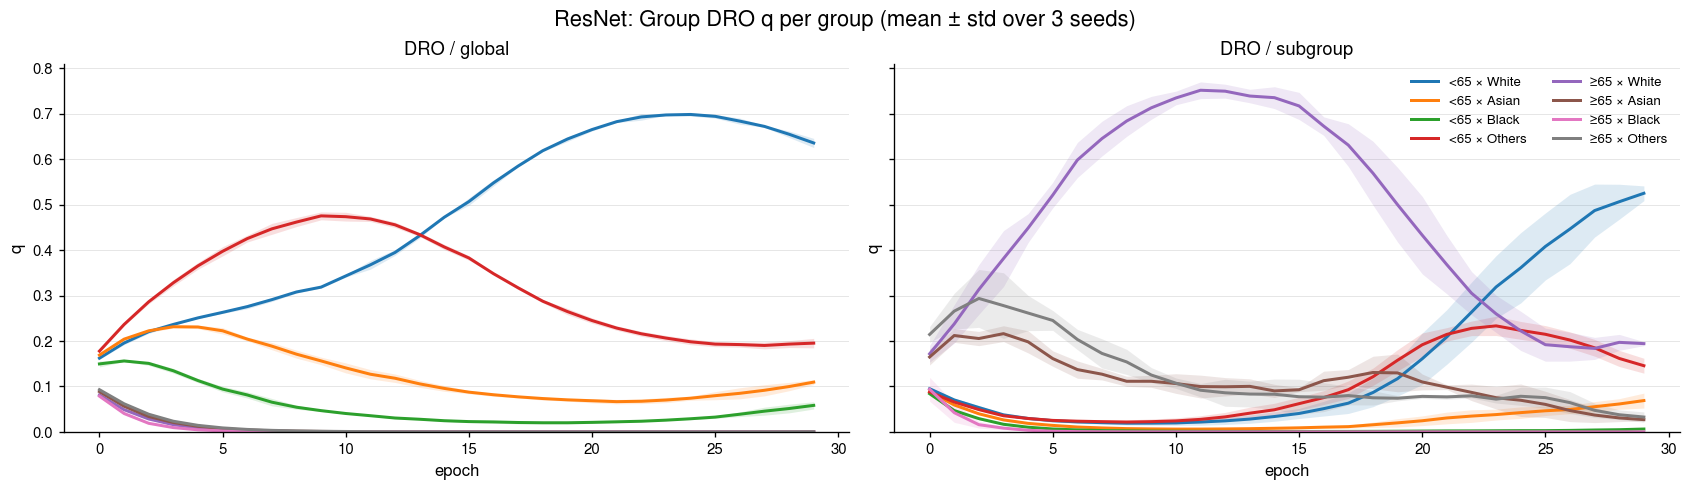

In [4]:
fig = plot_q_by_group("ResNet", {"DRO / global": "M02", "DRO / subgroup": "M11"})
fig.savefig(FIGURES / "resnet_q_history.png", dpi=160)
plt.show()

### 8群の性能

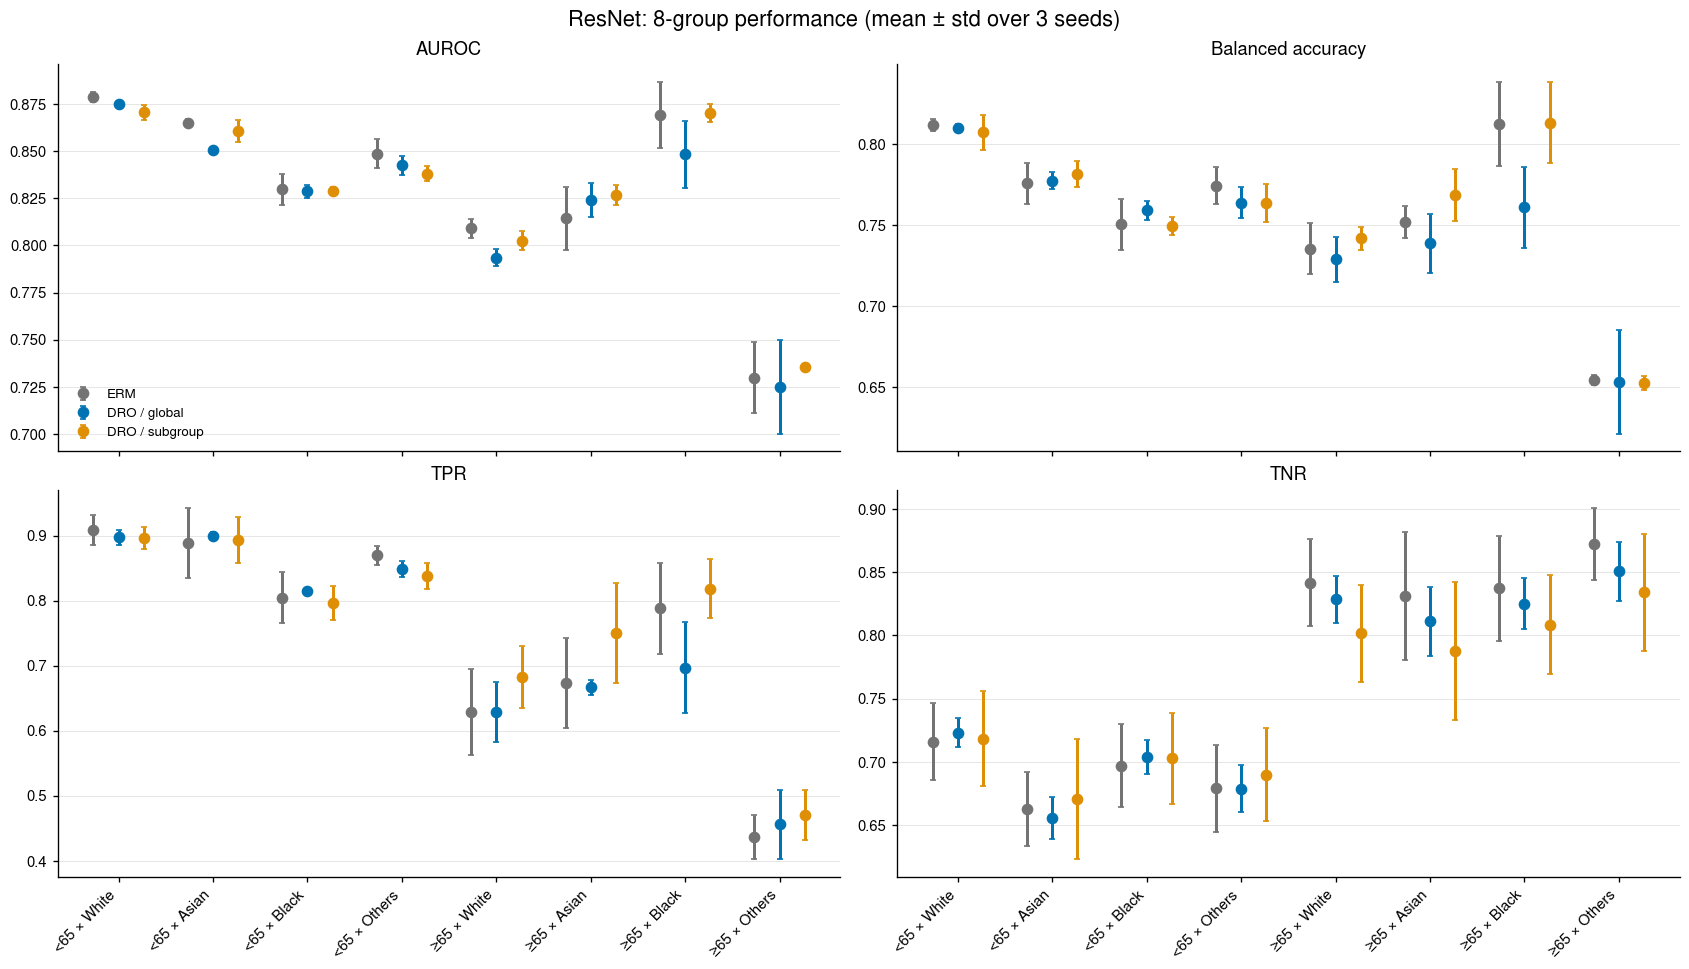

In [5]:
fig = plot_group_performance("ResNet", {"ERM": "M01", "DRO / global": "M02", "DRO / subgroup": "M11"})
fig.savefig(FIGURES / "resnet_subgroup_performance.png", dpi=160)
plt.show()

## Spatial LoRA

ResNetと同じ図。qの配分先と8群性能の変化がResNetと同じ向きかを見る。two-stageはqの推移を別の図に分け、8群の性能は1-stageと同じ図に重ねる。

### qの推移（1-stage）

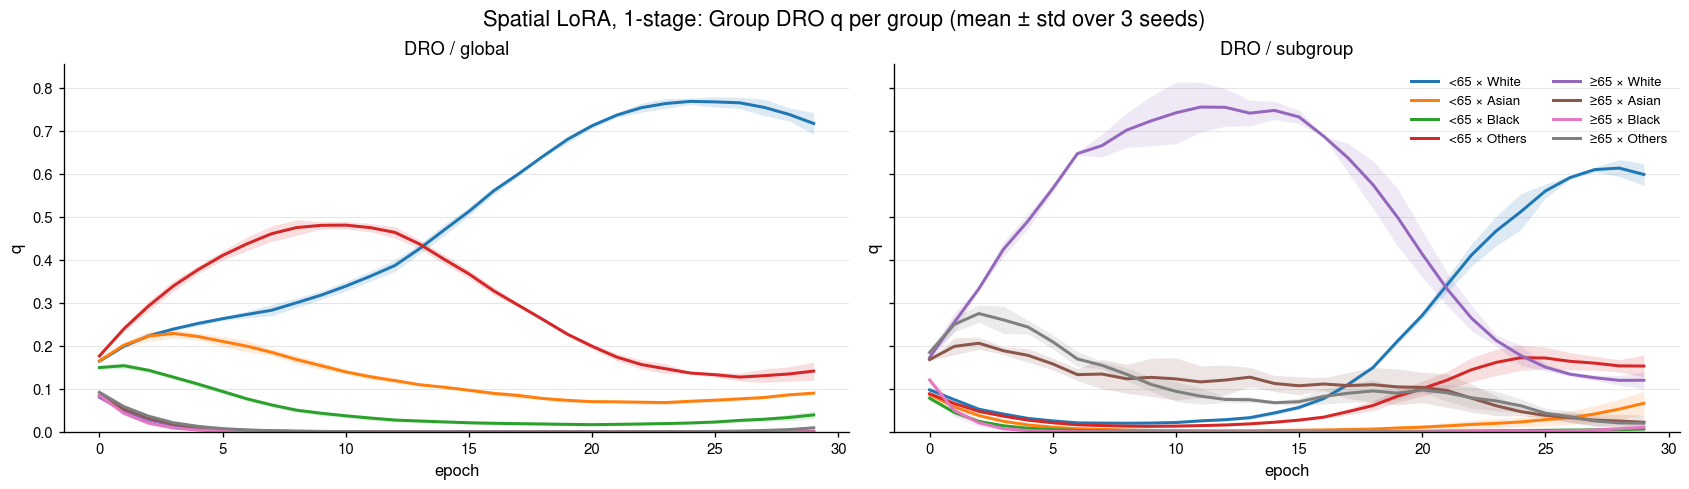

In [6]:
fig = plot_q_by_group("Spatial LoRA, 1-stage", {"DRO / global": "M04", "DRO / subgroup": "M12"})
fig.savefig(FIGURES / "spatial_lora_q_history.png", dpi=160)
plt.show()

### qの推移（two-stage）

backboneを凍結したまま学習するため、1-stageと群lossの推移が異なりうる。

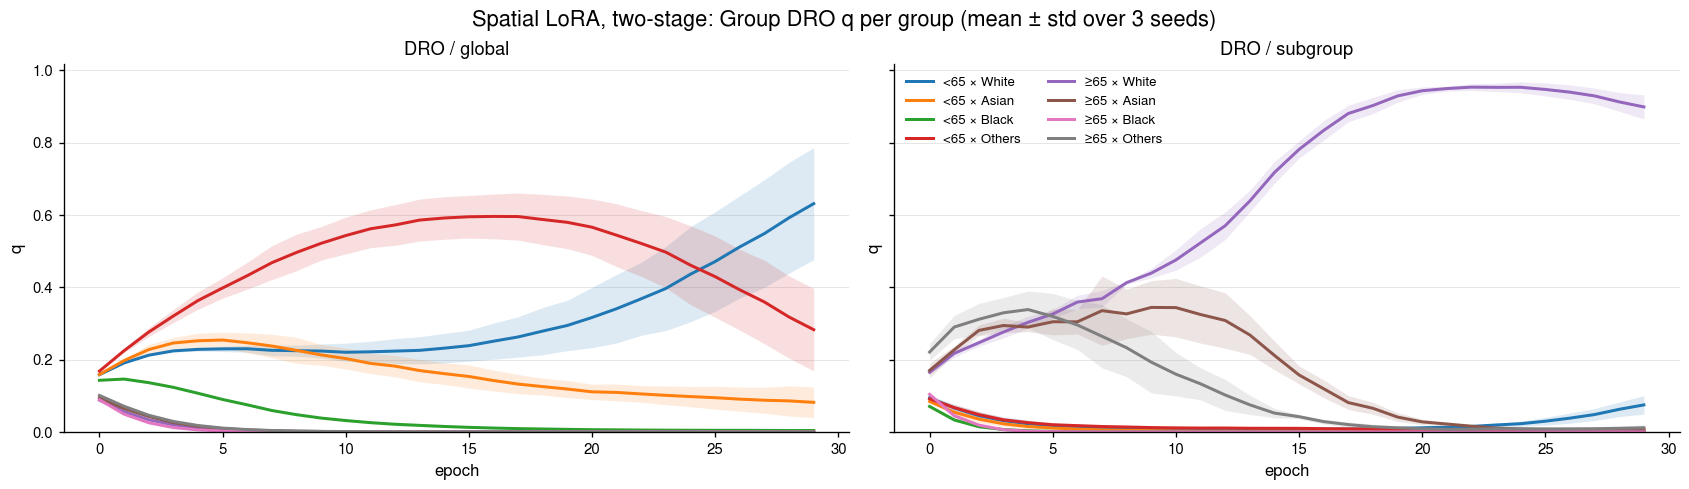

In [7]:
fig = plot_q_by_group("Spatial LoRA, two-stage", {"DRO / global": "M06", "DRO / subgroup": "M13"})
fig.savefig(FIGURES / "spatial_lora_two_stage_q_history.png", dpi=160)
plt.show()

### 8群の性能

ERMは1-stageのSpatial LoRA（M03）。two-stageの出発点であるResNet ERM（M01）はResNetの図にある。

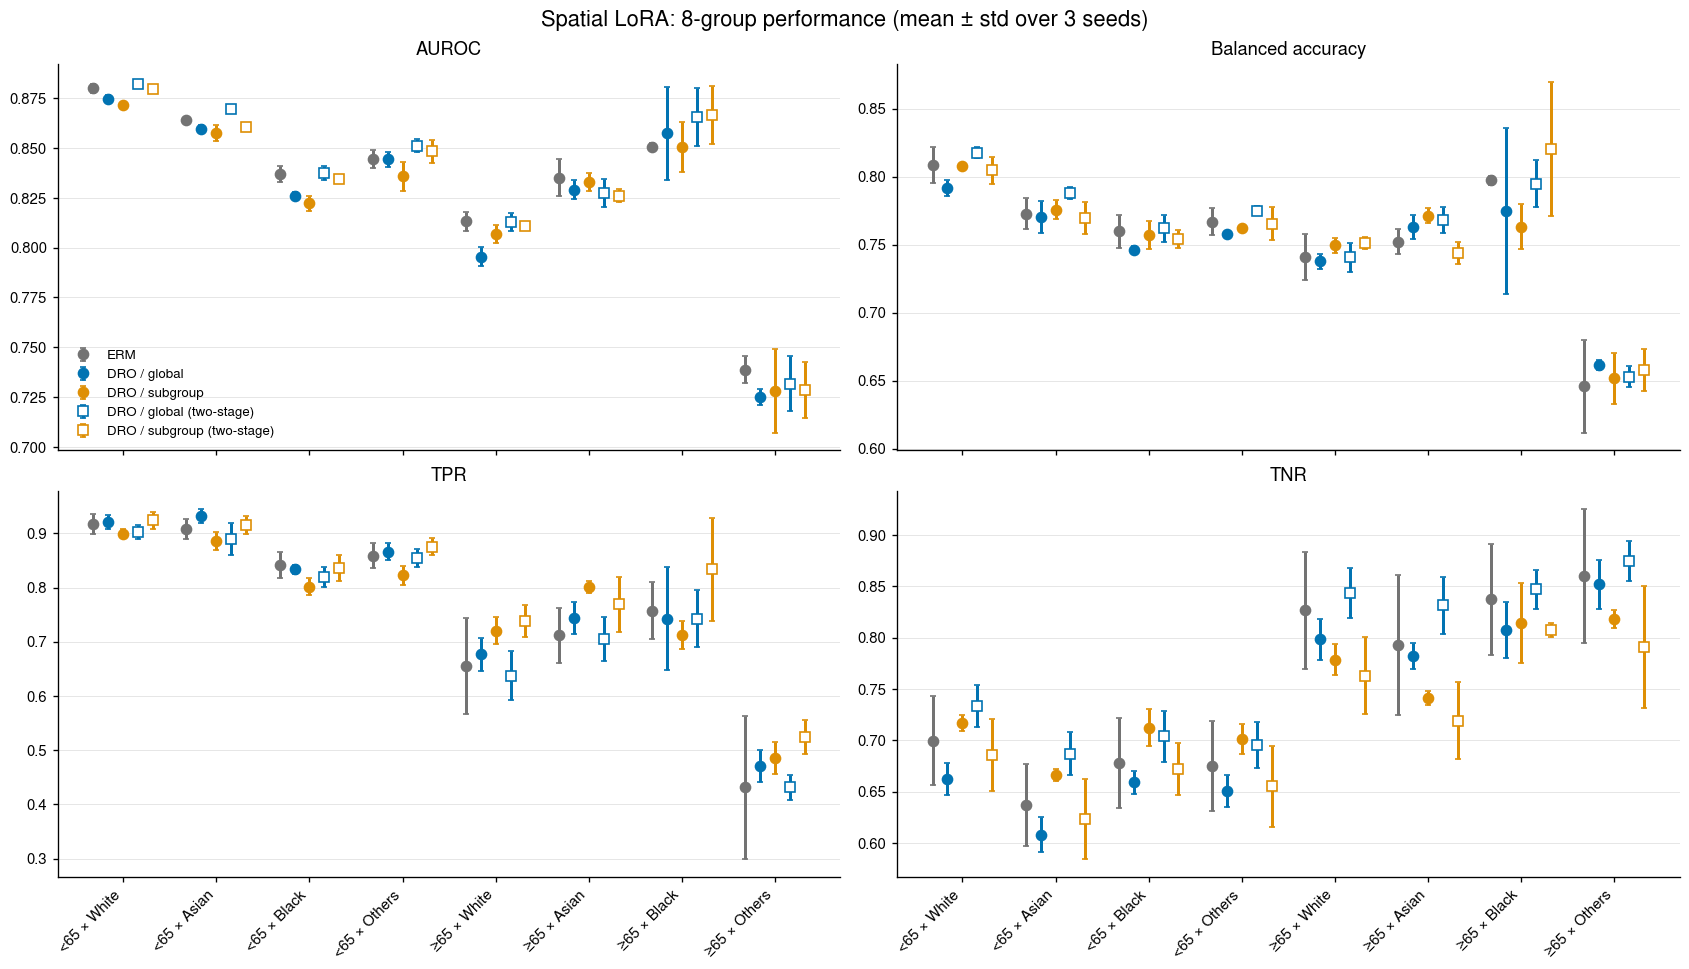

In [8]:
spatial = {
    "ERM": "M03",
    "DRO / global": "M04",
    "DRO / subgroup": "M12",
    "DRO / global (two-stage)": "M06",
    "DRO / subgroup (two-stage)": "M13",
}
fig = plot_group_performance("Spatial LoRA", spatial)
fig.savefig(FIGURES / "spatial_lora_subgroup_performance.png", dpi=160)
plt.show()

## ERMのモデル間比較

class weightの比較とは別に、DROを使わないERMどうしでモデル構成の差を見る。いずれも1-stage・global class weight。

### 全体の性能

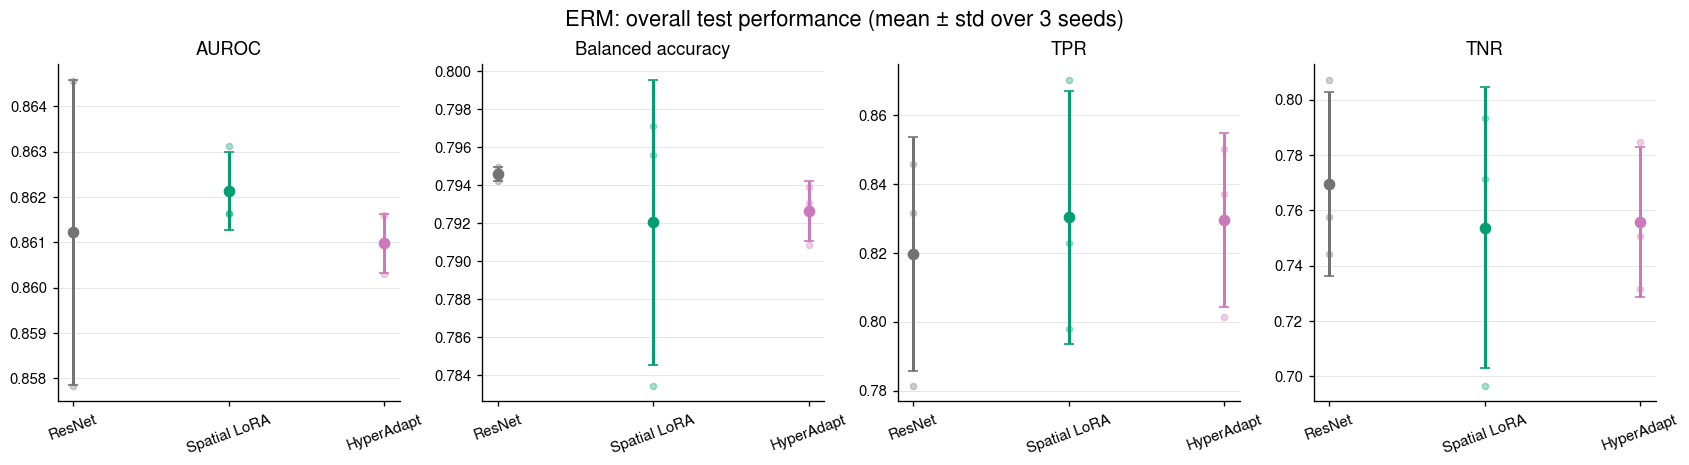

In [9]:
erm = {"ResNet": "M01", "Spatial LoRA": "M03", "HyperAdapt": "M07"}
fig = plot_overall_performance("ERM", erm)
fig.savefig(FIGURES / "erm_models_overall_performance.png", dpi=160)
plt.show()

### 8群の性能

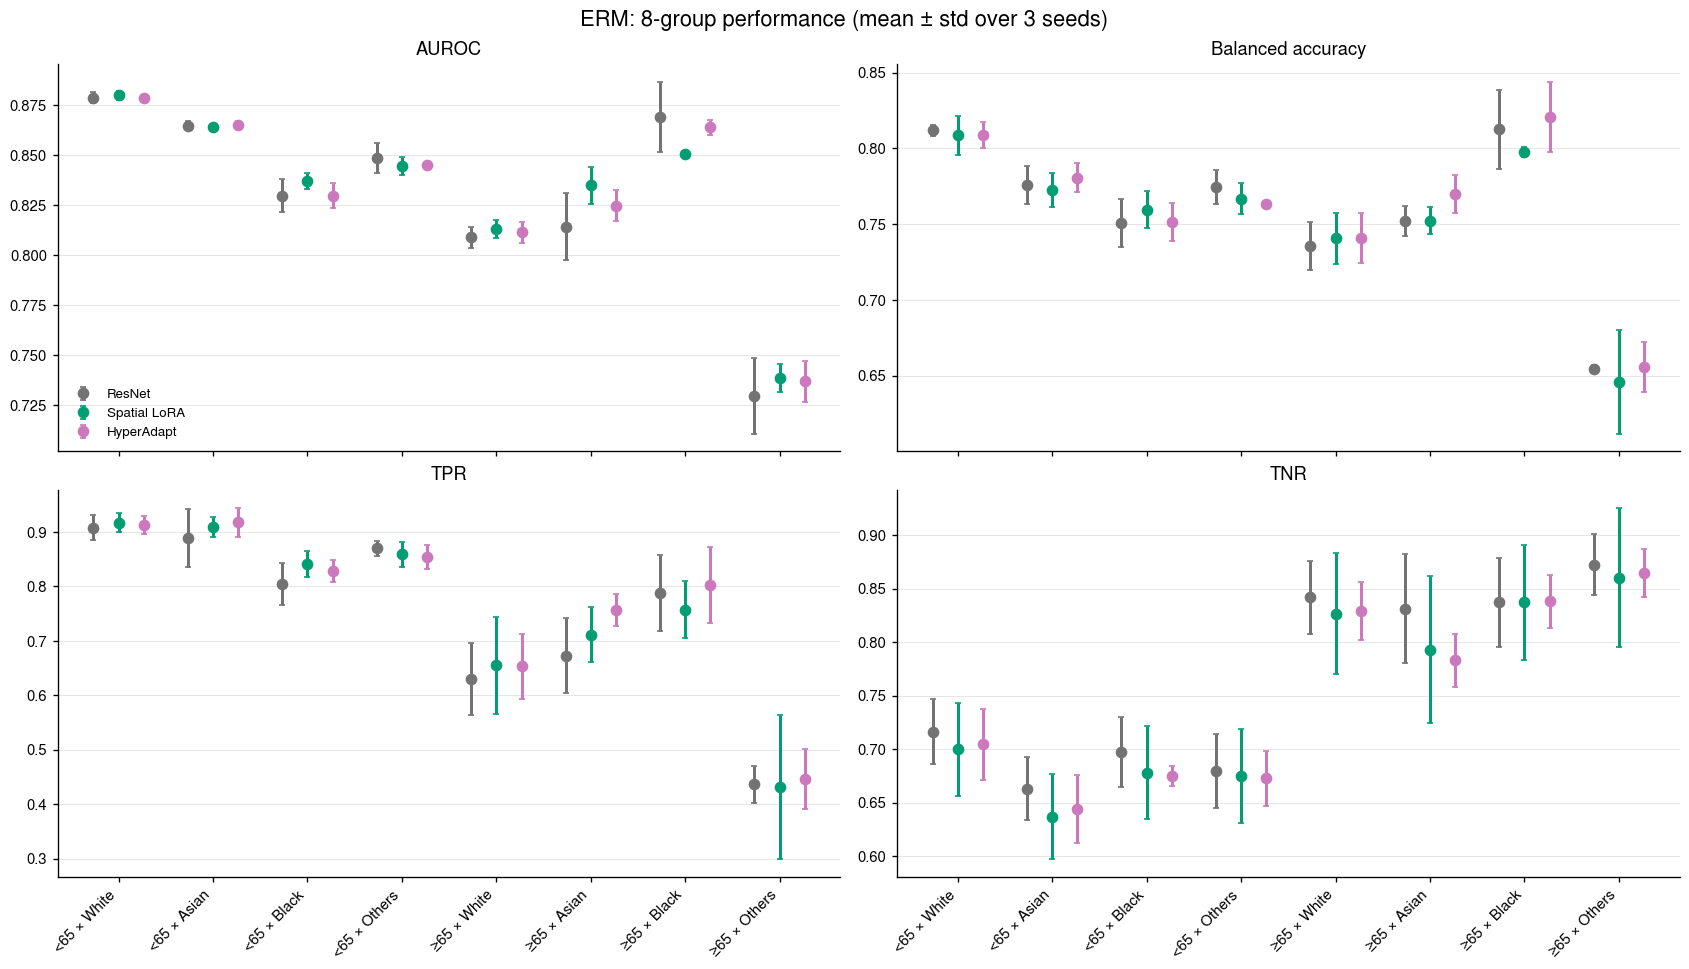

In [10]:
fig = plot_group_performance("ERM", erm)
fig.savefig(FIGURES / "erm_models_subgroup_performance.png", dpi=160)
plt.show()